# Amazon 2023: DUPGT with LLM-assisted supervision

Saved results from the completed single-seed pilot. This notebook reads the original outputs; it does not train a model or call the LLM. The experiment tests limited **bridge supervision**, while the separately pretrained Book/Movie factors stay fixed.

## 1. Load the saved experiment

Each rating row is one user–Movie rating. The same held-out users and 433,618 rating rows are used for every final comparison. New model choices were locked using validation results before final test evaluation.

In [1]:
from pathlib import Path
import sys, json, csv, gzip, html, itertools
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from dupgt_cdr.common import file_sha256, write_json

BASE = ROOT / "outputs/amazon2023/llm_transfer"
GRID = BASE / "validation_grid_v2_seed2020"
TEACHER = ROOT / "data/teacher/amazon2023/pilot"
read = lambda path: json.loads(Path(path).read_text())
grid = read(GRID / "grid_summary.json")
plan = read(GRID / "final_evaluation_plan.json")
selection = read(GRID / "final_selection.json")
completion = read(GRID / "evaluation_complete.json")
assert completion["status"] == "completed"
selection_hash = file_sha256(GRID / "final_selection.json")
for entry in selection["runs"]:
    run = Path(entry["run_dir"])
    assert file_sha256(run / "artifact_manifest.json") == entry["artifact_manifest_sha256"]
    assert read(run / "test_metrics.json")["selection_sha256"] == selection_hash
print("Trained models:", sum(len(g["runs"]) for g in grid["groups"]))
print("Models locked for final evaluation:", completion["evaluated_models"])
print("Transfer seeds:", completion["transfer_seeds"] )

Trained models: 14
Models locked for final evaluation: 9
Transfer seeds: [2020]


In [2]:
def table(rows, columns=None):
    if not rows:
        return
    columns = columns or list(rows[0])
    def value(v):
        if isinstance(v, float):
            return f"{v:.6f}"
        return str(v)
    head = "<tr>" + "".join("<th>" + html.escape(c) + "</th>" for c in columns) + "</tr>"
    body = "".join("<tr>" + "".join("<td>" + html.escape(value(r.get(c, ""))) + "</td>" for c in columns) + "</tr>" for r in rows)
    display(HTML("<table>" + head + body + "</table>"))

def export_csv(path, rows):
    with Path(path).open("w", newline="") as handle:
        writer = csv.DictWriter(handle, list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

## 2. What did the teacher supply?

The teacher is the pretrained local Qwen3.5-9B model. It is not fine-tuned. It sees three to six rated Books and ten real Movie/TV listings, then suggests relative preferences for five pairs. These are weak suggestions, not observed Movie ratings.

The text control uses TF-IDF word vectors and cosine similarity. The shuffled control reassigns LLM labels between users within each Movie pair, preserving the label budget and overall preference distribution. The primary training comparison uses only pair instances covered by both the LLM and text teacher.

In [3]:
generation = read(TEACHER / "generation_summary.json")
controls = read(TEACHER / "controls.json")
table([{
    "Source-only profiles": generation["responses"],
    "Possible comparisons": generation["requested_pairs"],
    "Decisive LLM preferences": generation["accepted_pairs"],
    "Common LLM/text pairs": controls["matched_pairs"],
    "Changed labels after shuffling": controls["changed_label_fraction"],
    "API cost": generation["api_cost"],
}])
print("Prompt version:", read(TEACHER / "generation.json")["prompt_version"])

Source-only profiles,Possible comparisons,Decisive LLM preferences,Common LLM/text pairs,Changed labels after shuffling,API cost
200,1000,970,927,0.235167,0


Prompt version: book-movie-pairs-v2


### Development check of teacher quality

“Accepted” means the response passed format/ID checks, not that the inferred preference is correct. After refining the task on an earlier development cohort, the revised prompt was checked on 20 different validation users. The results below compare choices with their hidden Movie-rating order. This is a small conditional diagnostic; teacher accuracy remains weak. These validation-user labels never enter bridge training. Accuracy is shown as a fraction: 0.5 means 50% of answered pairs.

In [4]:
audit = read(BASE / "teacher_audit_prompt_v2/comparison.json")
table([{
    "Teacher": r["model"], "Book profile": r["profile"], "Possible pairs": r["pairs"],
    "Answered": r["answered_pairs"], "Correct": r["correct_pairs"],
    "Accuracy when answered": r["accuracy_when_answered"],
} for r in audit["results"]])

Teacher,Book profile,Possible pairs,Answered,Correct,Accuracy when answered
dupgt-qwen35-9b,original,53,52,24,0.461538
dupgt-qwen35-9b,shuffled,53,49,19,0.387755
tfidf_text,original,53,52,29,0.557692
training_popularity,original,53,51,32,0.627451


## 3. Inspect one actual teacher example

These Book ratings are observed source data. The chosen Movie preferences are inferred. There is no hidden Movie-rating column for these source-only training users.

In [5]:
requests = [json.loads(line) for line in (TEACHER / "requests.jsonl").open()]
responses = [json.loads(line) for line in (TEACHER / "responses.jsonl").open()]
response = responses[0]["response"]
request = next(r for r in requests if r["request_id"] == response["request_id"])
table([{"Book": b["title"], "Actual Book rating": b["rating"]} for b in request["input"]["books"]])
movies = {m["alias"]: m["title"] for m in request["input"]["movies"]}
pairs = {p["pair_id"]: p for p in request["input"]["pairs"]}
examples = []
for choice in response["preferences"]:
    pair = pairs[choice["pair_id"]]
    alias = pair["a"] if choice["choice"] == "A" else pair["b"] if choice["choice"] == "B" else None
    examples.append({"Movie A": movies[pair["a"]], "Movie B": movies[pair["b"]],
                     "LLM suggestion": movies[alias] if alias else choice["choice"]})
table(examples)

Book,Actual Book rating
How It All Began: A Novel,5
The Case for Jesus: The Biblical and Historical Evidence for Christ,5
The Last Anniversary: A Novel,4
Safe Place,3
The Woman Outside My Door,3
Something in the Water: A Novel,3


Movie A,Movie B,LLM suggestion
Extreme Treks: Sacred Mountains of China,Spongebob Squarepants - Home Sweet Pineapple,Spongebob Squarepants - Home Sweet Pineapple
Outside the Bubble: On the Road with Alexandra Pelosi,American Masters: Johnny Carson: King of Late Night Blu-ray,Outside the Bubble: On the Road with Alexandra Pelosi
"Loves Music, Loves to Dance (Mary Higgins Clark Mystery Collection)",Earrings of Madame de...,Earrings of Madame de...
Marvel's Doctor Strange 2016 Region Free,Return to Nim's Island,Return to Nim's Island
The PJ's: Season 1,The Age Of Adaline,The Age Of Adaline


## 4. What was trained?

The independent Book/Movie factors remain frozen. Each run starts a fresh DUPGT transfer network. It minimizes real-rating squared error plus a small pairwise preference loss: $L=\mathrm{MSE}+\lambda\,\mathrm{softplus}(-(s_A-s_B))$ for A preferred over B. The terms are averaged separately.

$\lambda$ is the auxiliary-loss weight, not a confidence probability or DUPGT high/low gate. The no-teacher run supplies the zero-weight candidate. The LLM is not needed for ordinary rating prediction after training.

## 5. Validation grid and model selection

The percentages refer to shared training users: 1% uses 890 users and 10% uses 8,903 users. All observed Movie rows of the selected users are retained for bridge training. They do not reduce all Movie logs used for independent factor pretraining. Every run trains for 15 epochs; its saved checkpoint has the lowest validation RMSE. RMSE emphasizes large errors, so the selected checkpoint need not have the lowest MAE.

The grid has standard DUPGT plus text, LLM and shuffled supervision at weights 0.01 and 0.1. Weight zero is included through the shared baseline.

In [6]:
validation_rows = []
for group in grid["groups"]:
    for directory in group["runs"]:
        run = Path(directory)
        e, v = read(run / "experiment.json"), read(run / "validation_metrics.json")
        assert v["factors_unchanged"]
        validation_rows.append({"Supervision": f'{group["overlap_fraction"]:.0%}',
            "Method": e["teacher_kind"], "Weight": e["pseudo_weight"],
            "Real users": e["real_training_users"], "Real ratings": e["real_training_rows"],
            "Best epoch": v["selected_checkpoint"]["epoch"],
            "Validation MAE": v["raw"]["mae"], "Validation RMSE": v["raw"]["rmse"]})
table(validation_rows)
export_csv(GRID / "validation_results.csv", validation_rows)
print("Selection rule:", plan["selection_rule"])

Supervision,Method,Weight,Real users,Real ratings,Best epoch,Validation MAE,Validation RMSE
1%,none,0.000000,890,13792,2,0.800315,1.095315
1%,text,0.010000,890,13792,2,0.800282,1.094703
1%,text,0.100000,890,13792,2,0.800587,1.094335
1%,llm,0.010000,890,13792,2,0.800146,1.094667
1%,llm,0.100000,890,13792,2,0.801723,1.096913
1%,shuffled,0.010000,890,13792,2,0.800145,1.094664
1%,shuffled,0.100000,890,13792,2,0.801868,1.096921
10%,none,0.000000,8903,148359,12,0.739243,1.016196
10%,text,0.010000,8903,148359,12,0.736257,1.015539
10%,text,0.100000,8903,148359,12,0.740772,1.016377


Selection rule: Lowest saved validation RMSE including zero for each teacher family at the predeclared 1% and 10% supervision levels. Also retain text/shuffled controls at the LLM-selected weight for equal-weight attribution. No extension test metrics were read for selection; one transfer seed, exploratory pilot.


## 6. Primary final comparison: equal auxiliary weight

The LLM-selected weight was 0.01 at both supervision levels. Compare it with text and shuffled supervision at the same weight and with the no-teacher baseline. All final comparisons use the same test rows and the same pre-test selection record. Lower MAE/RMSE is better; a negative RMSE difference means lower error than matching standard DUPGT.

In [7]:
matched_rows = []
for group in plan["groups"]:
    baseline = read(Path(group["matched_runs"][0]) / "test_metrics.json")["raw"]
    for directory in group["matched_runs"]:
        run = Path(directory)
        e, t = read(run / "experiment.json"), read(run / "test_metrics.json")
        assert t["selection_sha256"] == selection_hash
        assert t["raw"]["n_ratings"] == 433618
        matched_rows.append({"Supervision": f'{group["overlap_fraction"]:.0%}', "Method": e["teacher_kind"],
            "Weight": e["pseudo_weight"], "Test MAE": t["raw"]["mae"], "Test RMSE": t["raw"]["rmse"],
            "RMSE minus matching DUPGT": t["raw"]["rmse"]-baseline["rmse"], "Test ratings": t["raw"]["n_ratings"]})
table(matched_rows)
export_csv(GRID / "final_matched_results.csv", matched_rows)

Supervision,Method,Weight,Test MAE,Test RMSE,RMSE minus matching DUPGT,Test ratings
1%,none,0.000000,0.813081,1.111242,0.000000,433618
1%,text,0.010000,0.812937,1.110654,-0.000588,433618
1%,llm,0.010000,0.812826,1.110646,-0.000595,433618
1%,shuffled,0.010000,0.812828,1.110641,-0.000601,433618
10%,none,0.000000,0.750512,1.030952,0.000000,433618
10%,text,0.010000,0.747743,1.030441,-0.000511,433618
10%,llm,0.010000,0.751112,1.030730,-0.000222,433618
10%,shuffled,0.010000,0.751018,1.030738,-0.000214,433618


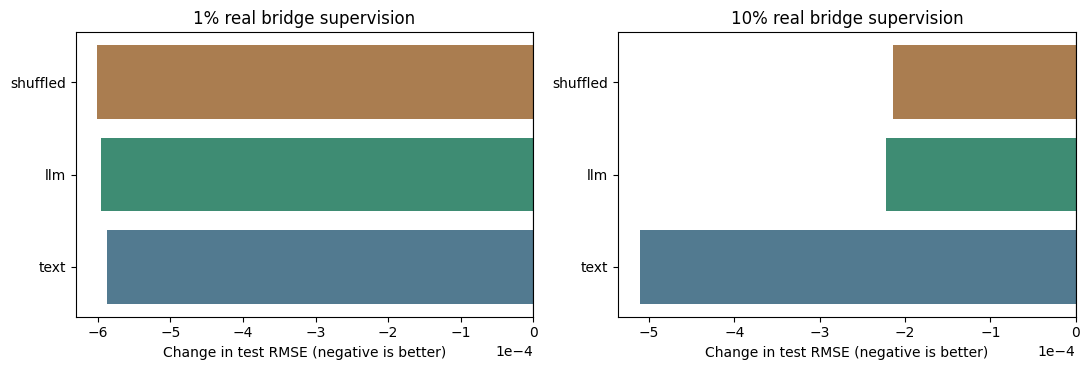

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, supervision in zip(axes, ("1%", "10%")):
    rows = [r for r in matched_rows if r["Supervision"] == supervision and r["Method"] != "none"]
    ax.barh([r["Method"] for r in rows], [r["RMSE minus matching DUPGT"] for r in rows], color=["#527a90", "#3e8c73", "#aa7d50"])
    ax.axvline(0, color="black", linewidth=.8)
    ax.set_title(f"{supervision} real bridge supervision")
    ax.set_xlabel("Change in test RMSE (negative is better)")
    ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
fig.tight_layout()
fig.savefig(GRID / "final_rmse_changes.png", dpi=160)
plt.show()

## 7. Secondary view: each family chooses its own weight

Each family chooses among zero, 0.01 and 0.1 using validation RMSE. At 1%, the text family selected 0.1 while LLM/shuffled selected 0.01. This table is a model-selection view; the equal-weight table above remains the primary control for attribution.

In [9]:
family_rows = []
for group in plan["groups"]:
    baseline = group["matched_runs"][0]
    selected = {"none": baseline, **group["validation_selected_families"]}
    for family, directory in selected.items():
        run = Path(directory)
        e, t = read(run / "experiment.json"), read(run / "test_metrics.json")
        family_rows.append({"Supervision": f'{group["overlap_fraction"]:.0%}', "Family": family,
            "Selected weight": e["pseudo_weight"], "Test MAE": t["raw"]["mae"], "Test RMSE": t["raw"]["rmse"]})
table(family_rows)
export_csv(GRID / "final_selected_family_results.csv", family_rows)

Supervision,Family,Selected weight,Test MAE,Test RMSE
1%,none,0.000000,0.813081,1.111242
1%,text,0.100000,0.813329,1.110458
1%,llm,0.010000,0.812826,1.110646
1%,shuffled,0.010000,0.812828,1.110641
10%,none,0.000000,0.750512,1.030952
10%,text,0.010000,0.747743,1.030441
10%,llm,0.010000,0.751112,1.030730
10%,shuffled,0.010000,0.751018,1.030738


## 8. Inspect saved predictions

These are the first eight test rows, chosen by file order. The model saw each user's Book history; their Movie rating was used only for evaluation. Catalogue titles may refer to separate editions or TV listings. Individual rows illustrate the output format; aggregate metrics above determine performance. Raw predictions can fall outside 1–5; clipped metrics are saved separately.

In [10]:
case = next(g for g in plan["groups"] if g["overlap_fraction"] == .1)
baseline_run = Path(case["matched_runs"][0])
llm_run = next(Path(p) for p in case["matched_runs"] if Path(p).name.startswith("llm_"))
def first_rows(path):
    with gzip.open(path, "rt") as handle:
        return list(itertools.islice(csv.DictReader(handle), 8))
a = first_rows(baseline_run / "test_predictions.csv.gz")
b = first_rows(llm_run / "test_predictions.csv.gz")
needed = {r["movie_asin"] for r in a}
titles = {}
with gzip.open(ROOT / "data/metadata/amazon2023/raw_selection/movies_source.jsonl.gz", "rt") as handle:
    for line in handle:
        row = json.loads(line)
        if row["asin"] in needed:
            titles[row["asin"]] = row["title"]
        if len(titles) == len(needed):
            break
examples = []
for left, right in zip(a, b):
    assert (left["user_id"], left["movie_asin"], left["actual_rating"]) == (right["user_id"], right["movie_asin"], right["actual_rating"])
    examples.append({"Movie/TV listing": titles.get(left["movie_asin"], left["movie_asin"]),
        "Actual rating": float(left["actual_rating"]), "DUPGT prediction": float(left["dupgt"]),
        "LLM-assisted prediction": float(right["dupgt"])})
table(examples)

Movie/TV listing,Actual rating,DUPGT prediction,LLM-assisted prediction
Smokey and the Bandit [Blu-ray],5.000000,4.560968,4.558389
Tom Hanks Double Feature (The Green Mile / Forrest Gump) [Blu-ray],5.000000,4.659778,4.643673
The Cannonball Run [Blu-ray],5.000000,4.116726,4.099693
Top Gun [Blu-ray],5.000000,4.368567,4.348328
Days Of Thunder [Blu-ray],5.000000,4.086271,4.098456
Wizard of Oz,5.000000,4.614401,4.585417
Silent Running,5.000000,4.145126,4.239466
Smile [DVD],5.000000,4.057351,4.058374


## 9. What do the results mean?

The pipeline is operational, but this pilot does not demonstrate a clear LLM-specific improvement. RMSE changes are tiny, and shuffled labels perform almost the same as personalised LLM labels. At 10% supervision, the selected LLM run slightly improves RMSE while worsening MAE. The text control remains competitive or better.

These findings do not show that LLM supervision can never help. They show that this particular local teacher, small fixed Movie pool and single-seed setup have not established a useful personalised contribution. More labels or a larger model should not be assumed to fix that without another controlled experiment.

## 10. Scope and reproducibility

- One transfer seed (2020), 200 source-only teacher users, ten candidate Movie/TV items.
- Domain factors were pretrained using full domain logs; only real bridge supervision was restricted.
- Static user-disjoint target-cold evaluation; no chronological or zero-overlap claim.
- Teacher choices are weak inferred labels, not observed interactions or calibrated confidence.
- Model choices were locked before final test evaluation. The original full-supervision 2023 baseline remains a separate reference (MAE 0.7230, RMSE 1.0119).
- Current runs have documented differences from the original paper's protocol.

Core code: `teacher.py` prepares/caches preferences; `experiments.py` trains matching bridges and locks/evaluates models; `train.py` defines the rating and pairwise losses. To inspect results again, run this notebook. To train another study, choose a new output directory; a test-evaluated grid cannot be extended. Saved checkpoints can be reused without pretraining again.